# ACF long-period limit: figures

Regenerates every figure in README.md from `data/` (plus a handful of
synthetic light curves re-simulated for the failure-mode panels). Heavy runs
live in `benchmarks/pb_scan.py` and `benchmarks/scorecard.py`; see README
"Reproduce".

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.simplefilter("ignore")
ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT / "claude_files"))
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
D = Path("data")
before = pd.read_csv(D / "pb_before_rows.csv")
after = pd.read_csv(D / "pb_after_rows.csv")
# validated categorical palette (dataviz validator: all checks pass); 'none' = neutral gray
OUT = ["correct", "half", "double", "wrong", "none"]
COL = {"correct": "#2a78d6", "half": "#eb6834", "double": "#1baf7a", "wrong": "#4a3aa7", "none": "#d9d8d3"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "font.size": 9})
print(len(before), len(after))

516 516


## 1. Outcome fractions vs P/B, before and after

Stacked bars per (baseline, P/B) cell, 12 light curves per cell (SNR 10, 1-3
spots, spot lifetime alternating infinite / 3P, solid-body). Diffrot is not
possible here (shear = 0), so it is omitted.

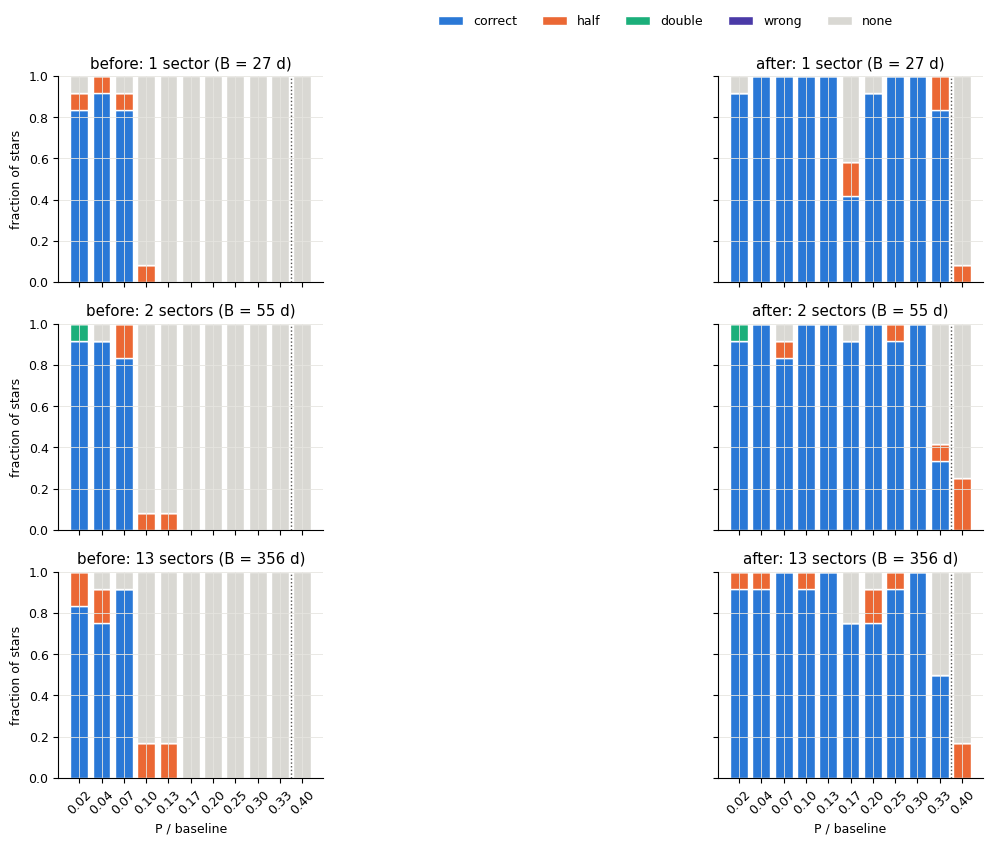

In [2]:
def fractions(df):
    s = df[df.kind == "signal"]
    t = s.groupby(["n_sectors", "P_over_B"]).outcome.value_counts(normalize=True).unstack().fillna(0)
    for o in OUT:
        if o not in t: t[o] = 0.0
    return t[OUT]

fb, fa = fractions(before), fractions(after)
fig, axes = plt.subplots(3, 2, figsize=(10, 8.5), sharex=True, sharey=True)
for i, ns in enumerate((1, 2, 13)):
    for j, (lab, f) in enumerate((("before", fb), ("after", fa))):
        ax = axes[i, j]; sub = f.loc[ns]
        x = np.arange(len(sub)); bottom = np.zeros(len(sub))
        for o in OUT:
            ax.bar(x, sub[o].values, bottom=bottom, color=COL[o], width=0.8, edgecolor="white", linewidth=1, label=o)
            bottom += sub[o].values
        ax.set_xticks(x, [f"{v:.2f}" for v in sub.index], rotation=45)
        ax.axvline(np.searchsorted(sub.index.values, 0.335) - 0.5, color="#52514e", ls=":", lw=1)
        ax.set_title(f"{lab}: {ns} sector{'s' if ns > 1 else ''} (B = {before[before.n_sectors == ns].baseline.iloc[0]:.0f} d)")
        if j == 0: ax.set_ylabel("fraction of stars")
        if i == 2: ax.set_xlabel("P / baseline")
axes[0, 1].legend(ncol=5, loc="lower left", bbox_to_anchor=(-1.1, 1.18), frameon=False)
fig.tight_layout(); fig.savefig(FIG / "outcomes_vs_PB.png", dpi=150); plt.show()

In [3]:
tab = pd.concat({"before": fb["correct"], "after": fa["correct"]}, axis=1).unstack(0).round(2)
tab

before             after            
n_sectors     1     2     13    1     2     13
P_over_B                                      
0.02        0.83  0.92  0.83  0.92  0.92  0.92
0.04        0.92  0.92  0.75  1.00  1.00  0.92
0.07        0.83  0.83  0.92  1.00  0.83  1.00
0.10        0.00  0.00  0.00  1.00  1.00  0.92
0.13        0.00  0.00  0.00  1.00  1.00  1.00
0.17        0.00  0.00  0.00  0.42  0.92  0.75
0.20        0.00  0.00  0.00  0.92  1.00  0.75
0.25        0.00  0.00  0.00  1.00  0.92  0.92
0.30        0.00  0.00  0.00  1.00  1.00  1.00
0.33        0.00  0.00  0.00  0.83  0.33  0.50
0.40        0.00  0.00  0.00  0.00  0.00  0.00

## 2. Pure-noise false positives

40 noise-only light curves per baseline (20 white, 20 white + AR(1) red noise
with sigma 0.001, tau 2 d). Left: false-positive rate; right: the periods the
pipeline claimed, vs baseline.

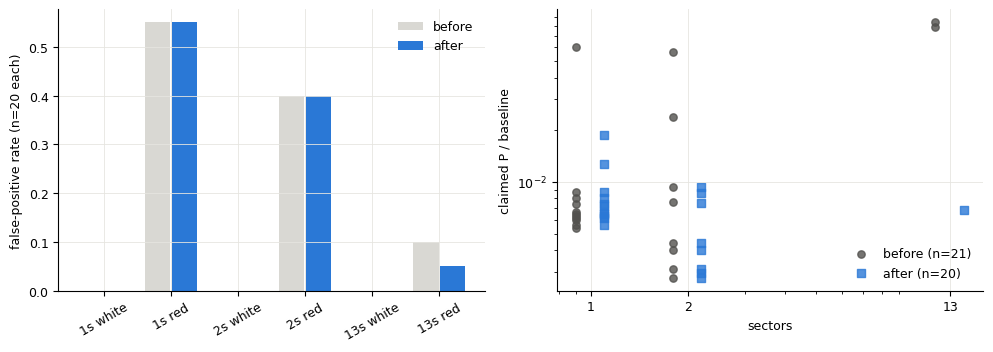

                 before  after
n_sectors red                 
1         False    0.00   0.00
          True     0.55   0.55
2         False    0.00   0.00
          True     0.40   0.40
13        False    0.00   0.00
          True     0.10   0.05


In [4]:
def fp(df):
    n = df[df.kind == "noise"].copy(); n["fp"] = n.outcome.eq("false_pos")
    return n
nb, na = fp(before), fp(after)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
grp = lambda n: n.groupby(["n_sectors", "red"]).fp.mean()
gb, ga = grp(nb), grp(na)
lbl = [f"{ns}s {'red' if r else 'white'}" for ns, r in gb.index]
x = np.arange(len(gb))
a1.bar(x - 0.2, gb.values, 0.38, color="#d9d8d3", label="before")
a1.bar(x + 0.2, ga.values, 0.38, color="#2a78d6", label="after")
a1.set_xticks(x, lbl, rotation=30); a1.set_ylabel("false-positive rate (n=20 each)"); a1.legend(frameon=False)
for lab, n, c, m in (("before", nb, "#52514e", "o"), ("after", na, "#2a78d6", "s")):
    f = n[n.fp]
    a2.scatter(f.n_sectors + (0.1 if lab == "after" else -0.1) * f.n_sectors, f.measured_P / f.baseline, s=28,
               color=c, marker=m, label=f"{lab} (n={len(f)})", alpha=0.8)
a2.set_xscale("log"); a2.set_yscale("log"); a2.set_xticks([1, 2, 13], ["1", "2", "13"])
a2.set_xlabel("sectors"); a2.set_ylabel("claimed P / baseline"); a2.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "noise_false_positives.png", dpi=150); plt.show()
print(pd.concat({"before": gb, "after": ga}, axis=1))

## 3. The few-peak flag: how often it fires and how precise those periods are

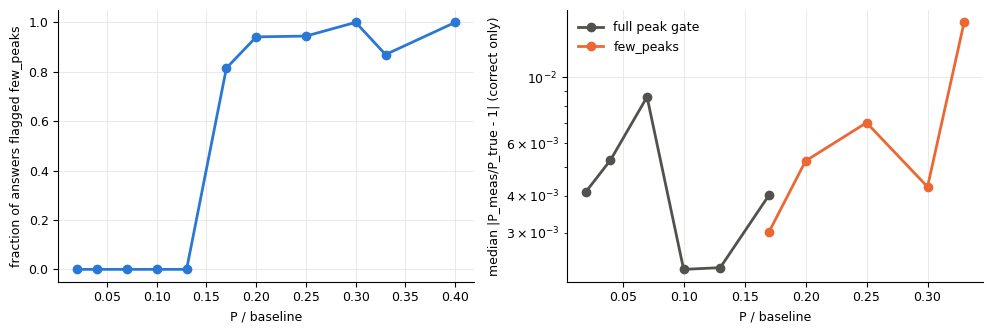

           count    mean     std  min     50%     90%     max
few_peaks                                                    
False      176.0  0.0097  0.0139  0.0  0.0028  0.0262  0.0779
True       144.0  0.0098  0.0140  0.0  0.0051  0.0207  0.0874


In [5]:
s = after[(after.kind == "signal") & after.outcome.eq("correct")].copy()
s["relerr"] = (s.measured_P / s.true_period - 1).abs()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
fr = after[(after.kind == "signal") & after.success].groupby("P_over_B").few_peaks.mean()
a1.plot(fr.index, fr.values, "-o", color="#2a78d6", lw=2, ms=6)
a1.set_xlabel("P / baseline"); a1.set_ylabel("fraction of answers flagged few_peaks")
for few, c, lab in ((False, "#52514e", "full peak gate"), (True, "#eb6834", "few_peaks")):
    g = s[s.few_peaks == few].groupby("P_over_B").relerr.median()
    a2.plot(g.index, g.values, "-o", color=c, lw=2, ms=6, label=lab)
a2.set_yscale("log"); a2.set_xlabel("P / baseline"); a2.set_ylabel("median |P_meas/P_true - 1| (correct only)")
a2.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "few_peaks_flag.png", dpi=150); plt.show()
print(s.groupby("few_peaks").relerr.describe(percentiles=[.5, .9]).round(4))

## 4. Dev-seed ablation (seed offset 500, 6 LCs/cell, 20 noise LCs per baseline)

Tuning and leave-one-out decisions were made on these seeds, not on the
evaluation seeds above. All variants run the final code with one option
changed (`--fit-kwargs`); "before" is the base commit.

In [6]:
dev = pd.read_csv(D / "dev_ablation_rows.csv")
def summ(g):
    s = g[g.kind == "signal"]; n = g[g.kind == "noise"]
    lo, mid = s[s.P_over_B <= 0.071], s[(s.P_over_B >= 0.099) & (s.P_over_B <= 0.335)]
    return pd.Series({"correct P/B<=0.07": lo.outcome.eq("correct").mean(),
                      "correct 0.10-0.33": mid.outcome.eq("correct").mean(),
                      "half 0.10-0.33": mid.outcome.eq("half").mean(),
                      "wrong (all)": s.outcome.eq("wrong").mean(),
                      "FP white": n[~n.red].outcome.eq("false_pos").mean(),
                      "FP red": n[n.red].outcome.eq("false_pos").mean(),
                      "FP red, P>0.1B": int((n.red & n.outcome.eq("false_pos") & (n.measured_P > 0.1 * n.baseline)).sum())})
abl = dev.groupby(["variant", "variant_desc"], sort=False).apply(summ).round(3)
abl

,,correct P/B<=0.07,correct 0.10-0.33,half 0.10-0.33,wrong (all),FP white,FP red,"FP red, P>0.1B"
variant,variant_desc,,,,,,,
before,base commit (before),0.833,0.000,0.032,0.010,0.0,0.400,0.0
final,FINAL,0.944,0.897,0.032,0.005,0.0,0.433,2.0
noweights,final without pair-count weights,0.944,0.897,0.032,0.005,0.0,0.433,2.0
noguard,final without factor-2 guard,0.870,0.833,0.095,0.005,0.0,0.433,2.0
notrim,final without decayed-tail trim,0.926,0.873,0.032,0.010,0.0,0.433,2.0
guard06,"final, guard threshold 0.6",0.944,0.889,0.040,0.005,0.0,0.433,2.0
guard08,"final, guard threshold 0.8",0.944,0.897,0.032,0.005,0.0,0.433,2.0


## 5. Runtime (P/B scan, same machine, 10 workers, before and after run separately)

In [7]:
def rt(df):
    t = df.stage1_seconds + df.fit_seconds
    return df.assign(total=t).groupby("n_sectors")[["total", "fit_seconds"]].quantile([0.5, 0.9]).unstack()
print("before"); print(rt(before).round(2)); print("after"); print(rt(after).round(2))
sb = json.load(open(D / "synth200_before_metrics.json")); sa = json.load(open(D / "synth200_after_metrics.json"))
print("synth200 runtime before", sb["runtime"], "after", sa["runtime"])

before
          total        fit_seconds       
            0.5    0.9         0.5    0.9
n_sectors                                
1          5.55   9.54        5.53   9.53
2          5.29   9.17        5.25   9.14
13         8.19  16.06        8.06  15.95
after
          total       fit_seconds      
            0.5   0.9         0.5   0.9
n_sectors                              
1          4.00  6.29        3.99  6.26
2          5.63  8.98        5.58  8.92
13         6.64  8.79        6.44  8.59
synth200 runtime before {'median_seconds': 12.361313684494235, 'p90_seconds': 16.88090877951181} after {'median_seconds': 6.552808849999565, 'p90_seconds': 8.583795889499015}


## 6. Representative remaining failures

Re-simulated from their seeds (same generator call as `benchmarks/pb_scan.py`).
Top: light curve. Bottom: ACF (to the new ~0.7 B limit) with the true period's
multiples (dashed gray), the selected period's comb (solid), and the old B/3
cut (dotted).

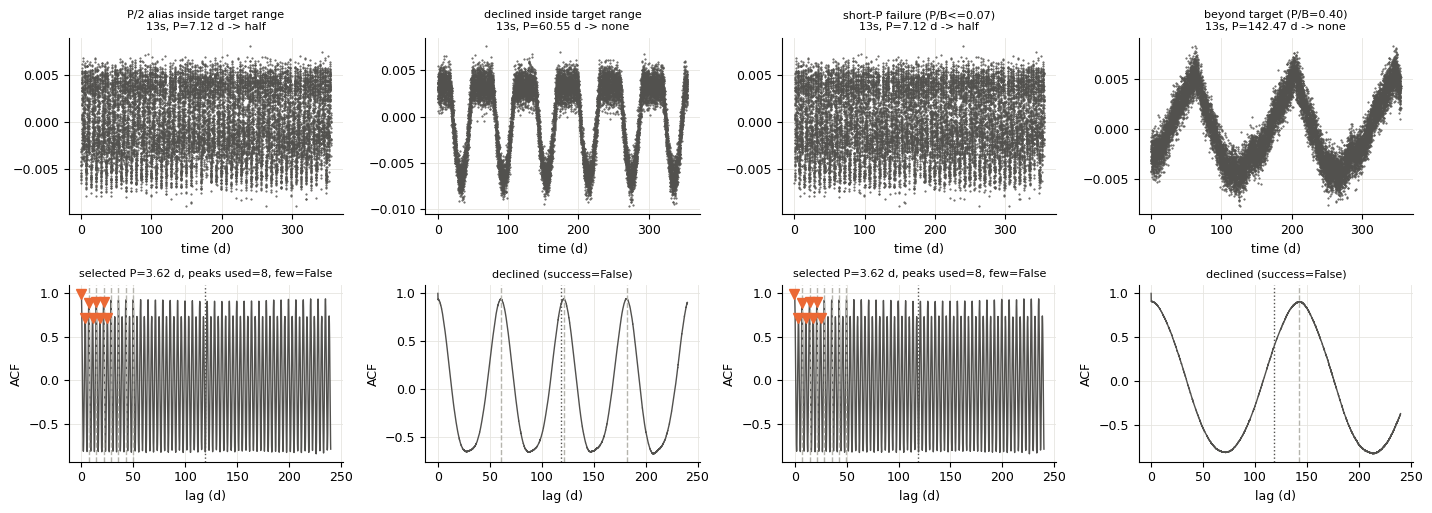

In [8]:
from synthetic import make_lightcurve
from acf_utils import compute_acf
from guesses import gather_initial_guesses
from comb_fit import fit_rotation_period

def resim(r):
    ns, seed = int(r.n_sectors), int(r.seed)
    if r.kind == "signal":
        P = r.true_period
        return make_lightcurve(P, amplitude=0.01, white_noise=0.001, n_sectors=ns, seed=seed, n_spots=1 + seed % 3,
                               spot_lifetime_days=np.inf if seed % 2 == 0 else 3 * P)
    return make_lightcurve(1.0, amplitude=0.0, white_noise=0.001, n_sectors=ns, seed=seed,
                           red_noise_sigma=0.001 if r.red else 0.0, red_noise_tau_days=2.0)

sig = after[after.kind == "signal"]; noi = after[after.kind == "noise"]
picks = []
for q, why in ((sig[(sig.outcome == "half") & (sig.P_over_B <= 0.335)], "P/2 alias inside target range"),
               (sig[(sig.outcome == "none") & (sig.P_over_B <= 0.335) & (sig.P_over_B >= 0.099)], "declined inside target range"),
               (sig[(sig.outcome != "correct") & (sig.P_over_B <= 0.071)], "short-P failure (P/B<=0.07)"),
               (noi[(noi.outcome == "false_pos") & (noi.measured_P > 0.1 * noi.baseline)], "red-noise long-period false positive"),
               (sig[(sig.outcome != "correct") & (sig.P_over_B > 0.39)], "beyond target (P/B=0.40)")):
    if len(q): picks.append((q.iloc[0], why))
fig, axes = plt.subplots(2, len(picks), figsize=(3.6 * len(picks), 5.2), squeeze=False)
for k, (r, why) in enumerate(picks):
    lc = resim(r)
    lags, acf, cnt = compute_acf(lc.time, lc.flux, return_counts=True)
    g, _ = gather_initial_guesses(lc.time, lc.flux, lags, acf, n_guesses=10)
    res = fit_rotation_period(lags, acf, g, acf_counts=cnt)
    a, b = axes[0, k], axes[1, k]
    a.plot(lc.time, lc.flux, ".", ms=1, color="#52514e")
    a.set_title(f"{why}\n{int(r.n_sectors)}s, " + (f"P={r.true_period:.2f} d" if r.kind == "signal" else "noise")
                + f" -> {r.outcome}", fontsize=8)
    a.set_xlabel("time (d)")
    b.plot(lags, acf, color="#52514e", lw=1)
    B = r.baseline
    b.axvline(B / 3, color="#52514e", ls=":", lw=1)
    if r.kind == "signal":
        for m in np.arange(1, 8) * r.true_period:
            if m < lags[-1]: b.axvline(m, color="#b5b4ad", ls="--", lw=1)
    if res.success:
        f = res.best_fit
        for n, pk in f.per_peak.items():
            b.plot(pk["center"], pk["height"], "v", color="#eb6834", ms=7)
        b.set_title(f"selected P={f.P:.2f} d, peaks used={f.n_peaks_used}, few={res.few_peaks}", fontsize=8)
    else:
        b.set_title("declined (success=False)", fontsize=8)
    b.set_xlabel("lag (d)"); b.set_ylabel("ACF")
fig.tight_layout(); fig.savefig(FIG / "failure_examples.png", dpi=150); plt.show()

## 7. synth200 regression check (13 sectors, log-uniform P 0.2-40 d)

In [9]:
rows = []
for key in ("final.overall.success", "final.overall.correct", "final.overall.diffrot", "final.overall.half",
            "final.overall.double", "final.overall.wrong", "final.overall.none"):
    get = lambda m: eval("m" + "".join(f"[{p!r}]" for p in key.split(".")))
    rows.append((key, get(sb), get(sa)))
pd.DataFrame(rows, columns=["metric", "before", "after"]).set_index("metric").round(3)

,before,after
metric,,
final.overall.success,0.670,0.725
final.overall.correct,0.460,0.495
final.overall.diffrot,0.210,0.230
final.overall.half,0.035,0.030
final.overall.double,0.000,0.000
final.overall.wrong,0.055,0.060
final.overall.none,0.240,0.185
